# Chapter 45: Pruning and forgetting

Checks [chapter 45](../../book/45-pruning-and-forgetting.md). The stand-in model is **linear in its weights**, as both
halves of the theorems are: `outputs = features @ weights` with fixed feature matrices, trained by the gradient step
`weights += learning_rate * features.T @ residual` (loss `0.5 * sum(residual ** 2)`). Pruning removes columns of the feature
matrix (weights). Forgetting uses two feature matrices on one set of weights, one per task. Everything is NumPy in
float64, seeded. These are measurements, not proofs: the proofs are in `Pruning.lean` and `Forgetting.lean`.
The travel of a task is the distance from the starting weights to the nearest fit (chapter 9); next to it the notebook
reports the starting vertical error, the length of the residual, because the loss sees only that one.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 45


def take_gradient_step(features, labels, learning_rate, weights):
    return weights + learning_rate * features.T @ (labels - features @ weights)


def run_gradient_steps(features, labels, learning_rate, step_count, start_weights=None):
    weights = np.zeros(features.shape[1]) if start_weights is None else start_weights.copy()
    for step in range(step_count):
        weights = take_gradient_step(features, labels, learning_rate, weights)
    return weights


def note_by_construction(label, holds, detail=""):
    """A property the code sets up on purpose. It is asserted so a typo stops the notebook, but it is not evidence."""
    print(f"[by construction, cannot fail] {label}" + (f"  ({detail})" if detail else ""))
    assert holds, f"setup broken: {label}"


def get_residual(features, labels, weights):
    return labels - features @ weights


def get_travel(features, labels, start_weights):
    """Distance from the start to the nearest weights that fit: the minimum-norm correction, via the pseudo-inverse."""
    return float(np.linalg.norm(np.linalg.pinv(features) @ get_residual(features, labels, start_weights)))

## Claim 0: the hand examples of the chapter

Pruning, learning rate 0.1: one label with starting error 1, kept strength 2 (one weight with feature `sqrt(2)`),
dropped strength 3 (one weight with feature `sqrt(3)`). Predicted, from the chapter: after 3 steps the whole model has
`0.5 ** 3 = 0.125` left and the pruned model `0.8 ** 3 = 0.512`. Forgetting, learning rate 0.2: old error 1, new error -4,
cross kernel 0.5; predicted old error after one step `1.4`. The chapter's check-yourself 2 (strengths 1 and 4, rate 0.1, 2 steps)
predicts `0.25` and `0.81`. A failure here would mean the notebook's step does not match the chapter's.

In [2]:
labels_one = np.array([1.0])
whole_features = np.array([[np.sqrt(2.0), np.sqrt(3.0)]])
kept_features = whole_features[:, :1]
whole_share = float(get_residual(whole_features, labels_one, run_gradient_steps(whole_features, labels_one, 0.1, 3))[0])
pruned_share = float(get_residual(kept_features, labels_one, run_gradient_steps(kept_features, labels_one, 0.1, 3))[0])
report("by hand: whole model has 0.125 of its error after 3 steps", abs(whole_share - 0.125) < 1e-12, f"measured {whole_share:.6f}")
report("by hand: pruned model has 0.512 of its error after 3 steps", abs(pruned_share - 0.512) < 1e-12, f"measured {pruned_share:.6f}")

old_features = np.array([[1.0, 0.0]])
new_features = np.array([[0.5, 0.5]])
old_labels, new_labels = np.array([1.0]), np.array([-4.0])
cross_kernel = float((old_features @ new_features.T)[0, 0])
stepped = take_gradient_step(new_features, new_labels, 0.2, np.zeros(2))
old_error_after = float(get_residual(old_features, old_labels, stepped)[0])
report("by hand: cross kernel 0.5, new error -4, rate 0.2 give old error 1.4", abs(old_error_after - 1.4) < 1e-12,
       f"cross kernel {cross_kernel}, measured {old_error_after:.6f}")

strength_features = np.array([[1.0, 2.0]])      # kept strength 1, dropped strength 4
whole_two = float(get_residual(strength_features, labels_one, run_gradient_steps(strength_features, labels_one, 0.1, 2))[0])
pruned_two = float(get_residual(strength_features[:, :1], labels_one, run_gradient_steps(strength_features[:, :1], labels_one, 0.1, 2))[0])
report("check yourself 2: shares 0.25 and 0.81", abs(whole_two - 0.25) < 1e-12 and abs(pruned_two - 0.81) < 1e-12,
       f"whole {whole_two:.4f}, pruned {pruned_two:.4f}")

[PASS] by hand: whole model has 0.125 of its error after 3 steps  (measured 0.125000)
[PASS] by hand: pruned model has 0.512 of its error after 3 steps  (measured 0.512000)
[PASS] by hand: cross kernel 0.5, new error -4, rate 0.2 give old error 1.4  (cross kernel 0.5, measured 1.400000)
[PASS] check yourself 2: shares 0.25 and 0.81  (whole 0.2500, pruned 0.8100)


True

## Claim 1: strengths add; pruning slows every direction (`IS_KERNEL_SUM`, `strengths_add`, `pruning_slows_a_direction_down`)

The model: 20 data points and 120 weights. Each weight has a feature column `scale * direction`, where the direction is
one of 20 fixed orthonormal directions of the label space (a random rotation). Then the kernel is diagonal in those directions,
and the strength of a direction is the sum of `scale ** 2` over the weights pointing at it. The labels use only 10 of the
directions. Six weights point at each used direction with scale in `[0.8, 1.2]`; six point at each unused
direction with scale in `[0.1, 0.3]`. Learning rate 0.05, 8 steps from zero weights.

**Predicted**, before running:

1. For a random split into kept and dropped weights, the whole kernel equals the kept kernel plus the dropped kernel to rounding.
2. For every fraction pruned, in either order, the measured share of the error left along each used direction is
   `(1 - learning_rate * kept_strength) ** step_count` to rounding, and is at least the whole model's share.
3. Control (the hypothesis broken): with a learning rate large enough that `learning_rate * whole_strength > 1`, the whole model
   overshoots and the inequality fails along some direction after some number of steps. If no such case exists, the control fails
   and the notebook stops.

In [3]:
generator = np.random.default_rng(SEED)
DATA_COUNT, USED_COUNT, WEIGHTS_PER_DIRECTION = 20, 10, 6
rotation, _ = np.linalg.qr(generator.standard_normal((DATA_COUNT, DATA_COUNT)))    # columns are the directions
direction_of_weight = np.repeat(np.arange(DATA_COUNT), WEIGHTS_PER_DIRECTION)
scale_of_weight = np.where(direction_of_weight < USED_COUNT,
                           generator.uniform(0.8, 1.2, direction_of_weight.size),
                           generator.uniform(0.1, 0.3, direction_of_weight.size))
WEIGHT_COUNT = direction_of_weight.size
all_features = rotation[:, direction_of_weight] * scale_of_weight                    # data_count by weight_count
label_coefficients = np.zeros(DATA_COUNT)
label_coefficients[:USED_COUNT] = generator.uniform(0.5, 1.5, USED_COUNT) * generator.choice([-1.0, 1.0], USED_COUNT)
labels = rotation @ label_coefficients
LEARNING_RATE, STEP_COUNT = 0.05, 8


def get_direction_strengths(weight_mask):
    return np.array([np.sum(scale_of_weight[weight_mask & (direction_of_weight == direction)] ** 2)
                     for direction in range(DATA_COUNT)])


whole_mask = np.ones(WEIGHT_COUNT, dtype=bool)
whole_strengths = get_direction_strengths(whole_mask)
note_by_construction("the learning rate is chosen so that rate * largest strength <= 1",
                     LEARNING_RATE * whole_strengths.max() <= 1.0, f"rate * largest strength {LEARNING_RATE * whole_strengths.max():.3f}")

# Prediction 1: kernel of the whole = kernel of kept + kernel of dropped, for random splits
worst_kernel_gap = 0.0
for trial in range(50):
    kept_mask = generator.random(WEIGHT_COUNT) < generator.uniform(0.1, 0.9)
    whole_kernel = all_features @ all_features.T
    kernel_sum = all_features[:, kept_mask] @ all_features[:, kept_mask].T + all_features[:, ~kept_mask] @ all_features[:, ~kept_mask].T
    worst_kernel_gap = max(worst_kernel_gap, np.abs(whole_kernel - kernel_sum).max())
report("whole kernel = kept kernel + dropped kernel, 50 random splits", worst_kernel_gap < 1e-12, f"largest gap {worst_kernel_gap:.1e}")


def get_shares(weight_mask, learning_rate=LEARNING_RATE, step_count=STEP_COUNT):
    """Measured share of the starting error left along each used direction, and the proved formula's value."""
    features = all_features[:, weight_mask]
    weights = run_gradient_steps(features, labels, learning_rate, step_count)
    residual_coefficients = rotation.T @ get_residual(features, labels, weights)
    measured = residual_coefficients[:USED_COUNT] / label_coefficients[:USED_COUNT]
    formula = (1 - learning_rate * get_direction_strengths(weight_mask)[:USED_COUNT]) ** step_count
    return measured, formula


whole_measured, whole_formula = get_shares(whole_mask)
report("the whole model's share along each used direction is (1 - rate * strength) ** steps",
       np.abs(whole_measured - whole_formula).max() < 1e-12, f"largest gap {np.abs(whole_measured - whole_formula).max():.1e}")

FRACTIONS = np.linspace(0.0, 0.95, 20)
order_smallest_first = np.argsort(scale_of_weight)
formula_gap, below_whole = 0.0, 0.0
for fraction in FRACTIONS:
    drop_count = int(round(fraction * WEIGHT_COUNT))
    for ordering in (order_smallest_first, generator.permutation(WEIGHT_COUNT)):
        kept_mask = np.ones(WEIGHT_COUNT, dtype=bool)
        kept_mask[ordering[:drop_count]] = False
        measured, formula = get_shares(kept_mask)
        formula_gap = max(formula_gap, np.abs(measured - formula).max())
        below_whole = max(below_whole, (whole_measured - measured).max())            # must be <= 0: pruned share >= whole share
report("pruned share along each used direction is (1 - rate * kept strength) ** steps, 20 fractions, 2 orders",
       formula_gap < 1e-10, f"largest gap {formula_gap:.1e}")
report("pruned share >= whole share along every used direction (pruning_slows_a_direction_down)", below_whole < 1e-12,
       f"largest whole minus pruned {below_whole:.1e}")

# Control: a rate big enough that the whole model overshoots
BIG_RATE = 0.4
print(f"control: rate * whole strength along the strongest direction = {BIG_RATE * whole_strengths.max():.2f}")
worst_violation = -np.inf
for step_count in range(1, 9):
    for fraction in (0.3, 0.6):
        kept_mask = np.ones(WEIGHT_COUNT, dtype=bool)
        kept_mask[order_smallest_first[:int(fraction * WEIGHT_COUNT)]] = False
        measured_whole, _ = get_shares(whole_mask, BIG_RATE, step_count)
        measured_pruned, _ = get_shares(kept_mask, BIG_RATE, step_count)
        worst_violation = max(worst_violation, (measured_whole - measured_pruned).max())
report("control: with rate * strength well above 1 the whole share can exceed the pruned share", worst_violation > 1.0,
       f"largest whole minus pruned {worst_violation:.2f}")

[by construction, cannot fail] the learning rate is chosen so that rate * largest strength <= 1  (rate * largest strength 0.349)
[PASS] whole kernel = kept kernel + dropped kernel, 50 random splits  (largest gap 5.3e-15)
[PASS] the whole model's share along each used direction is (1 - rate * strength) ** steps  (largest gap 2.6e-16)
[PASS] pruned share along each used direction is (1 - rate * kept strength) ** steps, 20 fractions, 2 orders  (largest gap 6.7e-16)
[PASS] pruned share >= whole share along every used direction (pruning_slows_a_direction_down)  (largest whole minus pruned 7.2e-16)
control: rate * whole strength along the strongest direction = 2.79
[PASS] control: with rate * strength well above 1 the whole share can exceed the pruned share  (largest whole minus pruned 49.14)


True

## Claim 2: a winning ticket costs nothing, random pruning does (`winning_ticket`), with the figure

The same model. The 60 smallest weights are exactly the ones pointing at the ten directions the labels never use. They are built
that way: **whether magnitude pruning finds such a ticket in a real network is not tested** (the chapter lists it as open). What is
tested is the theorem's side: where the dropped weights have no strength along a direction the labels use, pruned and whole keep the same error.

**Predicted:** pruning the 60 smallest leaves the residual identical to the whole model's (difference at rounding), at every
step. Pruning 60 weights at random drops strength along used directions, so the residual after 8 steps is larger than the whole
model's. A random prune that does not exceed the whole model's error by at least 10 percent on average over 20 draws would count
against the claim that pruning costs in general.
The figure shows the error left (the length of the residual divided by its starting length) against the fraction pruned, for the smallest-first
order (measured by training), for random orders (measured, mean with min to max), the whole model's value (measured), and the value from the formula of claim 1 (from the formula, not a run).

[PASS] pruning the 60 smallest weights leaves the residual unchanged at 21 step counts  (largest entry difference 4.4e-16)
error left after 8 steps: whole 0.0590; at fraction 0.50: smallest first 0.0590, random mean 0.3596
random mean / whole at fraction 0.5: 6.09
[PASS] random pruning near one half costs at least 10 percent more error than the whole model  (random mean / whole 6.09)
[PASS] smallest-first below the ticket size costs nothing (error equals the whole model's)  (fractions up to 0.5)
[PASS] smallest-first beyond the ticket costs something  (at fraction 0.95: 0.783 against 0.059)
[PASS] the curve computed from the formula matches the measured (gradient descent) smallest-first curve  (largest gap 1.7e-16)


wrote book/figures/45-pruning-smallest-against-random.png


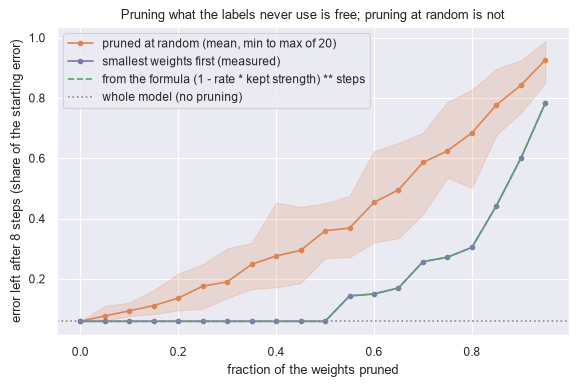

In [4]:
def get_error_left(weight_mask, step_count=STEP_COUNT):
    features = all_features[:, weight_mask]
    weights = run_gradient_steps(features, labels, LEARNING_RATE, step_count)
    return float(np.linalg.norm(get_residual(features, labels, weights)) / np.linalg.norm(labels))


def get_formula_error_left(weight_mask):
    shares = (1 - LEARNING_RATE * get_direction_strengths(weight_mask)[:USED_COUNT]) ** STEP_COUNT
    return float(np.linalg.norm(shares * label_coefficients[:USED_COUNT]) / np.linalg.norm(label_coefficients))


ticket_kept = np.ones(WEIGHT_COUNT, dtype=bool)
ticket_kept[order_smallest_first[:60]] = False
worst_difference = 0.0
for step_count in range(0, 21):
    whole_residual = get_residual(all_features, labels, run_gradient_steps(all_features, labels, LEARNING_RATE, step_count))
    ticket_residual = get_residual(all_features[:, ticket_kept], labels,
                                   run_gradient_steps(all_features[:, ticket_kept], labels, LEARNING_RATE, step_count))
    worst_difference = max(worst_difference, np.abs(whole_residual - ticket_residual).max())
report("pruning the 60 smallest weights leaves the residual unchanged at 21 step counts", worst_difference < 1e-12,
       f"largest entry difference {worst_difference:.1e}")

DRAW_COUNT = 20
smallest_curve, random_curves, formula_curve = [], [], []
for fraction in FRACTIONS:
    drop_count = int(round(fraction * WEIGHT_COUNT))
    kept_mask = np.ones(WEIGHT_COUNT, dtype=bool)
    kept_mask[order_smallest_first[:drop_count]] = False
    smallest_curve.append(get_error_left(kept_mask))
    formula_curve.append(get_formula_error_left(kept_mask))
    draws = []
    for draw in range(DRAW_COUNT):
        random_mask = np.ones(WEIGHT_COUNT, dtype=bool)
        random_mask[generator.permutation(WEIGHT_COUNT)[:drop_count]] = False
        draws.append(get_error_left(random_mask))
    random_curves.append(draws)
random_curves = np.array(random_curves)
whole_error_left = get_error_left(whole_mask)
half_index = int(np.argmin(np.abs(FRACTIONS - 0.5)))
random_half_mean = random_curves[half_index].mean()
print(f"error left after {STEP_COUNT} steps: whole {whole_error_left:.4f}; "
      f"at fraction {FRACTIONS[half_index]:.2f}: smallest first {smallest_curve[half_index]:.4f}, random mean {random_half_mean:.4f}")
print(f"random mean / whole at fraction 0.5: {random_half_mean / whole_error_left:.2f}")
report("random pruning near one half costs at least 10 percent more error than the whole model",
       random_half_mean > 1.10 * whole_error_left, f"random mean / whole {random_half_mean / whole_error_left:.2f}")
report("smallest-first below the ticket size costs nothing (error equals the whole model's)",
       all(abs(value - whole_error_left) < 1e-12 for value, fraction in zip(smallest_curve, FRACTIONS) if fraction <= 0.5),
       "fractions up to 0.5")
report("smallest-first beyond the ticket costs something", smallest_curve[-1] > 1.5 * whole_error_left,
       f"at fraction {FRACTIONS[-1]:.2f}: {smallest_curve[-1]:.3f} against {whole_error_left:.3f}")
report("the curve computed from the formula matches the measured (gradient descent) smallest-first curve", np.abs(np.array(formula_curve) - np.array(smallest_curve)).max() < 1e-10,
       f"largest gap {np.abs(np.array(formula_curve) - np.array(smallest_curve)).max():.1e}")

figure, axis = plt.subplots(figsize=(6.6, 4))
axis.fill_between(FRACTIONS, random_curves.min(axis=1), random_curves.max(axis=1), color=VERTICAL, alpha=0.2)
axis.plot(FRACTIONS, random_curves.mean(axis=1), "-o", color=VERTICAL, markersize=3, label="pruned at random (mean, min to max of 20)")
axis.plot(FRACTIONS, smallest_curve, "-o", color=MODEL, markersize=3, label="smallest weights first (measured)")
axis.plot(FRACTIONS, formula_curve, "--", color=BOUND, label="from the formula (1 - rate * kept strength) ** steps")
axis.axhline(whole_error_left, color=BEFORE, linestyle=":", label="whole model (no pruning)")
axis.set_xlabel("fraction of the weights pruned")
axis.set_ylabel(f"error left after {STEP_COUNT} steps (share of the starting error)")
axis.set_title("Pruning what the labels never use is free; pruning at random is not")
axis.legend(loc="upper left")
save_figure(figure, "45-pruning-smallest-against-random")
plt.show()

## Claim 3: the fit moves farther, by the exchange rate (`pruning_moves_the_fit_farther`)

Tight features on both sides: 8 data points, kept features `sqrt(1) * Q1.T` and dropped features `sqrt(3) * Q2.T`, where `Q1` and `Q2`
(30 rows each, 8 orthonormal columns) come from two separate random QR factorisations. Then
the kept kernel is `1 * identity`, the dropped kernel `3 * identity`, the whole kernel `4 * identity`. From zero weights, the
whole model's travel is the starting error over `sqrt(4)` and the pruned model's is the starting error over `sqrt(1)`.

**Predicted:** pruned travel `times sqrt(1)` equals whole travel `times sqrt(4)` to rounding, the pruned travel is twice the whole
travel, and gradient descent run to convergence travels the same distance as the pseudo-inverse says. The two have the same starting
vertical error, the length of the label vector, so the longer travel is not caused by a bigger error. Control (tightness broken): rows of
the kept features scaled by random factors in `[0.5, 1.5]`; then the product identity must fail by more than 1 percent.

In [5]:
generator = np.random.default_rng(SEED + 1)
TIGHT_DATA, HALF_WEIGHTS = 8, 30
# each side is tight on its own: orthonormalise the two blocks separately
block_one, _ = np.linalg.qr(generator.standard_normal((HALF_WEIGHTS, TIGHT_DATA)))
block_two, _ = np.linalg.qr(generator.standard_normal((HALF_WEIGHTS, TIGHT_DATA)))
kept_tight, dropped_tight = 1.0 * block_one.T, np.sqrt(3.0) * block_two.T
whole_tight = np.hstack([kept_tight, dropped_tight])
note_by_construction("kept kernel is 1 * identity, whole kernel is 4 * identity (orthonormal blocks scaled)",
       np.allclose(kept_tight @ kept_tight.T, np.eye(TIGHT_DATA), atol=1e-12) and np.allclose(whole_tight @ whole_tight.T, 4 * np.eye(TIGHT_DATA), atol=1e-12))
tight_labels = generator.standard_normal(TIGHT_DATA)
KEPT_STRENGTH, WHOLE_STRENGTH = 1.0, 4.0
pruned_travel = get_travel(kept_tight, tight_labels, np.zeros(HALF_WEIGHTS))
whole_travel = get_travel(whole_tight, tight_labels, np.zeros(2 * HALF_WEIGHTS))
starting_error = float(np.linalg.norm(tight_labels))
print(f"starting vertical error {starting_error:.4f}; travel pruned {pruned_travel:.4f}, whole {whole_travel:.4f}")
report("pruned travel * sqrt(kept strength) = whole travel * sqrt(whole strength)",
       abs(pruned_travel * np.sqrt(KEPT_STRENGTH) - whole_travel * np.sqrt(WHOLE_STRENGTH)) < 1e-12,
       f"{pruned_travel * np.sqrt(KEPT_STRENGTH):.6f} against {whole_travel * np.sqrt(WHOLE_STRENGTH):.6f}")
report("the pruned travel is twice the whole travel", abs(pruned_travel / whole_travel - 2.0) < 1e-12, f"ratio {pruned_travel / whole_travel:.6f}")
report("travel = starting error / sqrt(strength) on each side",
       abs(pruned_travel - starting_error / np.sqrt(KEPT_STRENGTH)) < 1e-12 and abs(whole_travel - starting_error / np.sqrt(WHOLE_STRENGTH)) < 1e-12)
gd_pruned = np.linalg.norm(run_gradient_steps(kept_tight, tight_labels, 0.2, 200))
gd_whole = np.linalg.norm(run_gradient_steps(whole_tight, tight_labels, 0.2, 200))
report("gradient descent to convergence travels the same distances", abs(gd_pruned - pruned_travel) < 1e-9 and abs(gd_whole - whole_travel) < 1e-9,
       f"descent {gd_pruned:.6f} and {gd_whole:.6f}")

loose_kept = kept_tight * generator.uniform(0.5, 1.5, size=(TIGHT_DATA, 1))
loose_whole = np.hstack([loose_kept, dropped_tight])
loose_product_gap = abs(get_travel(loose_kept, tight_labels, np.zeros(HALF_WEIGHTS)) * np.sqrt(KEPT_STRENGTH)
                        - get_travel(loose_whole, tight_labels, np.zeros(2 * HALF_WEIGHTS)) * np.sqrt(WHOLE_STRENGTH))
report("control: with the kept rows of unequal lengths the product identity fails", loose_product_gap > 0.01 * starting_error,
       f"gap {loose_product_gap:.3f} against starting error {starting_error:.3f}")

[by construction, cannot fail] kept kernel is 1 * identity, whole kernel is 4 * identity (orthonormal blocks scaled)
starting vertical error 1.9523; travel pruned 1.9523, whole 0.9761
[PASS] pruned travel * sqrt(kept strength) = whole travel * sqrt(whole strength)  (1.952296 against 1.952296)
[PASS] the pruned travel is twice the whole travel  (ratio 2.000000)
[PASS] travel = starting error / sqrt(strength) on each side
[PASS] gradient descent to convergence travels the same distances  (descent 1.952296 and 0.976148)
[PASS] control: with the kept rows of unequal lengths the product identity fails  (gap 0.153 against starting error 1.952)


True

## Claim 4: a step on a new task changes the old errors only through the cross kernel (`forgetting_goes_through_the_cross_kernel`, `separate_features_forget_nothing`)

One set of 40 weights, an old task with 10 data points (feature matrix `old_features`) and a new task with 6 (`new_features`). From random
starting weights, one gradient step on the new task must change the old residual by exactly `-learning_rate * old_features @ new_features.T @ new_residual`
(the cross kernel applied to the new error), to rounding. A separate construction gives a cross kernel of zero (the new rows lie in
directions orthogonal to every old row); then 100 steps on the new task must leave the old residual exactly where it was. **Predicted:**
differences at rounding, in both. Control: new rows that overlap the old rows (cross kernel not zero) must change the old residual
by more than 1 percent of its length.

In [6]:
generator = np.random.default_rng(SEED + 2)
WEIGHT_DIM, OLD_COUNT, NEW_COUNT = 40, 10, 6
basis, _ = np.linalg.qr(generator.standard_normal((WEIGHT_DIM, WEIGHT_DIM)))
old_features = basis[:, :OLD_COUNT].T * generator.uniform(0.8, 1.6, size=(OLD_COUNT, 1))
orthogonal_new = basis[:, OLD_COUNT:OLD_COUNT + NEW_COUNT].T * generator.uniform(0.8, 1.6, size=(NEW_COUNT, 1))
overlap_new = 0.6 * (generator.standard_normal((NEW_COUNT, OLD_COUNT)) @ old_features) / np.sqrt(OLD_COUNT) + 0.8 * orthogonal_new
old_labels = generator.standard_normal(OLD_COUNT)
new_labels = 3.0 * generator.standard_normal(NEW_COUNT)
NEW_RATE_FRACTION = 0.5


def get_safe_rate(new_features):
    return NEW_RATE_FRACTION / np.linalg.eigvalsh(new_features @ new_features.T).max()


worst_identity_gap = 0.0
for trial in range(50):
    start_weights = generator.standard_normal(WEIGHT_DIM)
    learning_rate = generator.uniform(0.01, 0.2)
    for new_features in (orthogonal_new, overlap_new):
        stepped = take_gradient_step(new_features, new_labels, learning_rate, start_weights)
        old_after = get_residual(old_features, old_labels, stepped)
        old_before = get_residual(old_features, old_labels, start_weights)
        new_residual = get_residual(new_features, new_labels, start_weights)
        cross_push = old_features @ (new_features.T @ new_residual)
        worst_identity_gap = max(worst_identity_gap, np.abs(old_after - (old_before - learning_rate * cross_push)).max())
report("old residual after = old residual before - rate * cross kernel @ new residual, 100 random cases",
       worst_identity_gap < 1e-12, f"largest entry gap {worst_identity_gap:.1e}")

cross_orthogonal = np.abs(old_features @ orthogonal_new.T).max()
cross_overlap = np.abs(old_features @ overlap_new.T).max()
print(f"largest cross kernel entry: orthogonal {cross_orthogonal:.1e}, overlapping {cross_overlap:.3f}")
start_weights = generator.standard_normal(WEIGHT_DIM)
old_before = get_residual(old_features, old_labels, start_weights)
after_orthogonal = get_residual(old_features, old_labels, run_gradient_steps(orthogonal_new, new_labels, get_safe_rate(orthogonal_new), 100, start_weights))
after_overlap = get_residual(old_features, old_labels, run_gradient_steps(overlap_new, new_labels, get_safe_rate(overlap_new), 100, start_weights))
report("zero cross kernel: 100 steps on the new task leave the old residual unchanged", np.abs(after_orthogonal - old_before).max() < 1e-12,
       f"largest entry change {np.abs(after_orthogonal - old_before).max():.1e}")
overlap_change = np.linalg.norm(after_overlap - old_before) / np.linalg.norm(old_before)
report("control: with overlapping features the old residual changes by more than 1 percent", overlap_change > 0.01,
       f"relative change {overlap_change:.2f}")

[PASS] old residual after = old residual before - rate * cross kernel @ new residual, 100 random cases  (largest entry gap 1.8e-15)
largest cross kernel entry: orthogonal 2.3e-16, overlapping 0.835
[PASS] zero cross kernel: 100 steps on the new task leave the old residual unchanged  (largest entry change 6.7e-16)
[PASS] control: with overlapping features the old residual changes by more than 1 percent  (relative change 0.60)


True

## Claim 5: the change is at most the old features' size times the new task's travel (`forgetting_is_at_most_predict_size_times_travel`), with the figure

The theorem assumes gradient descent fits the new task exactly. For the weights, the old task is fit first
(`start_weights = pinv(old_features) @ old_labels`, so the old error starts at zero and any later old error is forgetting). The
new task is trained to a fit: for the tight new features, one step at `learning_rate = 1 / strength` fits exactly (the exact hypothesis);
for the other new features, 3000 steps bring the new residual below `1e-10`, and the bound is checked with a slack of `1e-8` (the hypothesis holds only to that tolerance).
`‖old_features‖` is the largest singular value. The travel is measured from the start to the nearest fit, with the vertical
error (the starting length of the new residual) printed beside it.

**Predicted:** in every case the change in the old residual, `‖old residual after - old residual before‖`, is at most
`‖old_features‖ * travel`. The control breaks the hypothesis that the fit is the one gradient descent reaches: take a fit that adds a random
null-space direction of the new features at distance 3 times the travel (still a fit, but not the nearest);
the bound with the travel must then fail for at least one case of 200, and the failure is reported.
The figure shows the length of the old residual against steps on the new task, for the overlapping and the orthogonal new
task, each with its ceiling. The ceiling is the same constant at every step, since descent never moves farther than the travel.

[by construction, cannot fail] the old task starts fit: old error is zero (the start is the pseudo-inverse solution)
[PASS] tight new features, one exact step: change <= ||old features|| * travel, 40 starts  (largest change minus ceiling -1.59e+00)


[PASS] descent-fitted new tasks (overlapping and orthogonal): change <= ceiling, 80 cases (slack 1e-8)  (largest change / ceiling 0.423)
[PASS] control: a fit that is not the nearest can break the ceiling  (164 of 200 cases above the ceiling, largest excess 5.317)
overlapping: new task vertical error at start 3.901, travel 3.800, ceiling 5.786, old error after 80 steps 2.000
orthogonal: new task vertical error at start 4.655, travel 4.307, ceiling 6.557, old error after 80 steps 0.000
[PASS] old error rises for the overlapping task and stays zero for the orthogonal one, below the ceiling at every step  (overlapping peak 2.000, orthogonal peak 3.2e-15)
wrote book/figures/45-forgetting-against-steps.png


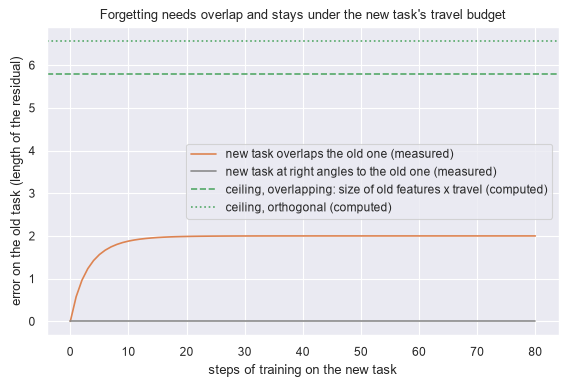

In [7]:
generator = np.random.default_rng(SEED + 3)
old_start = np.linalg.pinv(old_features) @ old_labels
old_norm = np.linalg.norm(old_features, 2)
note_by_construction("the old task starts fit: old error is zero (the start is the pseudo-inverse solution)",
                     np.linalg.norm(get_residual(old_features, old_labels, old_start)) < 1e-12)

tight_new, _ = np.linalg.qr(generator.standard_normal((WEIGHT_DIM, NEW_COUNT)))
tight_new = 2.0 * tight_new.T
tight_gap = -np.inf
for trial in range(40):
    start_weights = old_start + 0.5 * generator.standard_normal(WEIGHT_DIM)
    trained = take_gradient_step(tight_new, new_labels, 1.0 / 4.0, start_weights)
    fit_error = np.linalg.norm(get_residual(tight_new, new_labels, trained))
    assert fit_error < 1e-12
    change = np.linalg.norm(get_residual(old_features, old_labels, trained) - get_residual(old_features, old_labels, start_weights))
    tight_gap = max(tight_gap, change - old_norm * get_travel(tight_new, new_labels, start_weights))
report("tight new features, one exact step: change <= ||old features|| * travel, 40 starts", tight_gap <= 1e-12,
       f"largest change minus ceiling {tight_gap:.2e}")

closest_ratio = 0.0
for trial in range(40):
    start_weights = old_start + 0.5 * generator.standard_normal(WEIGHT_DIM)
    for new_features in (orthogonal_new, overlap_new):
        trained = run_gradient_steps(new_features, new_labels, get_safe_rate(new_features), 3000, start_weights)
        assert np.linalg.norm(get_residual(new_features, new_labels, trained)) < 1e-10
        change = np.linalg.norm(get_residual(old_features, old_labels, trained) - get_residual(old_features, old_labels, start_weights))
        ceiling = old_norm * get_travel(new_features, new_labels, start_weights)
        assert change <= ceiling + 1e-8, (change, ceiling)
        closest_ratio = max(closest_ratio, change / ceiling)
report("descent-fitted new tasks (overlapping and orthogonal): change <= ceiling, 80 cases (slack 1e-8)", closest_ratio <= 1 + 1e-8,
       f"largest change / ceiling {closest_ratio:.3f}")

# Control: a fit that is not the nearest one
violations, worst_excess = 0, 0.0
for trial in range(200):
    start_weights = old_start + 0.5 * generator.standard_normal(WEIGHT_DIM)
    new_features = overlap_new
    nearest_move = np.linalg.pinv(new_features) @ get_residual(new_features, new_labels, start_weights)
    travel = np.linalg.norm(nearest_move)
    null_direction = generator.standard_normal(WEIGHT_DIM)
    null_direction -= np.linalg.pinv(new_features) @ (new_features @ null_direction)       # remove the part the new task sees
    null_direction *= 3.0 * travel / np.linalg.norm(null_direction)
    far_fit = start_weights + nearest_move + null_direction
    assert np.linalg.norm(get_residual(new_features, new_labels, far_fit)) < 1e-9
    change = np.linalg.norm(get_residual(old_features, old_labels, far_fit) - get_residual(old_features, old_labels, start_weights))
    excess = change - old_norm * travel
    violations += excess > 0
    worst_excess = max(worst_excess, excess)
report("control: a fit that is not the nearest can break the ceiling", violations > 0,
       f"{violations} of 200 cases above the ceiling, largest excess {worst_excess:.3f}")

# The figure: old error against steps on the new task
start_weights = old_start.copy()
STEPS_SHOWN = 80
figure_curves, figure_ceilings = {}, {}
for name, new_features in (("overlapping", overlap_new), ("orthogonal", orthogonal_new)):
    rate = get_safe_rate(new_features)
    weights = start_weights.copy()
    errors = [np.linalg.norm(get_residual(old_features, old_labels, weights))]
    for step in range(STEPS_SHOWN):
        weights = take_gradient_step(new_features, new_labels, rate, weights)
        errors.append(np.linalg.norm(get_residual(old_features, old_labels, weights)))
    figure_curves[name] = np.array(errors)
    travel = get_travel(new_features, new_labels, start_weights)
    figure_ceilings[name] = old_norm * travel
    print(f"{name}: new task vertical error at start {np.linalg.norm(get_residual(new_features, new_labels, start_weights)):.3f}, "
          f"travel {travel:.3f}, ceiling {figure_ceilings[name]:.3f}, old error after {STEPS_SHOWN} steps {errors[-1]:.3f}")
report("old error rises for the overlapping task and stays zero for the orthogonal one, below the ceiling at every step",
       figure_curves["overlapping"].max() > 0.1 and figure_curves["orthogonal"].max() < 1e-10
       and all(figure_curves[name].max() <= figure_ceilings[name] + 1e-10 for name in figure_curves),
       f"overlapping peak {figure_curves['overlapping'].max():.3f}, orthogonal peak {figure_curves['orthogonal'].max():.1e}")

figure, axis = plt.subplots(figsize=(6.6, 4))
axis.plot(figure_curves["overlapping"], "-", color=VERTICAL, label="new task overlaps the old one (measured)")
axis.plot(figure_curves["orthogonal"], "-", color=BEFORE, label="new task at right angles to the old one (measured)")
axis.axhline(figure_ceilings["overlapping"], color=BOUND, linestyle="--", label="ceiling, overlapping: size of old features x travel (computed)")
axis.axhline(figure_ceilings["orthogonal"], color=BOUND, linestyle=":", label="ceiling, orthogonal (computed)")
axis.set_xlabel("steps of training on the new task")
axis.set_ylabel("error on the old task (length of the residual)")
axis.set_title("Forgetting needs overlap and stays under the new task's travel budget")
axis.legend(loc="center right")
save_figure(figure, "45-forgetting-against-steps")
plt.show()